# 02 – Standardisation, Splits and Baselines

Builds on `01_data_audit.ipynb`. The audit showed:

- 76 % of the cleaned molecules are penetrating, so accuracy is not a useful headline metric
- A single polarity descriptor (TPSA) already separates the classes well (single-feature AUC about 0.83 when
  oriented correctly), so any fingerprint or graph model has to beat a descriptor model
- Scaffold groups are diverse (1020 scaffolds for 1965 molecules, 76 % of them singletons), but several larger groups
  are almost pure (steroids, benzodiazepines, phenothiazines, barbiturates). A random split lets a model profit from
  near-copies of these.

**Goals**
- Standardise molecules (largest fragment) and re-check duplicates
- Build physicochemical, ECFP4 and combined feature sets
- Compare a **random split** with a **randomised scaffold split**, each repeated 10 times
- Quantify how optimistic the random split is (scores and nearest-neighbour similarity)
- Train baselines and report ROC-AUC, PR-AUC and balanced accuracy with their spread across splits

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RDLogger.DisableLog("rdApp.*")
plt.style.use("seaborn-v0_8")
RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

clean_path = DATA_PROCESSED / "bbbp_clean.csv"
assert clean_path.exists(), f"{clean_path} not found. Run 01_data_audit.ipynb first."

## 2. Standardisation

Salts and multi-fragment entries are reduced to their **largest fragment**, because the counter-ion does not
determine permeability but would distort descriptors and fingerprints. Charges are not neutralised: the charge state
can carry real information (for example permanently charged quaternary ammonium compounds). Afterwards, duplicates and
label conflicts are checked again, since two different salts of one drug now collapse into one molecule.

In [2]:
clean = pd.read_csv(clean_path)
chooser = rdMolStandardize.LargestFragmentChooser()


def standardise(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return Chem.MolToSmiles(chooser.choose(mol))


clean["std_smiles"] = clean["smiles"].apply(standardise)
assert clean["std_smiles"].notna().all()
n_changed = int((clean["std_smiles"] != clean["smiles"]).sum())

grouped = clean.groupby("std_smiles")["label"]
conflicting = grouped.nunique()[lambda s: s > 1].index

no_conflict = clean[~clean["std_smiles"].isin(conflicting)]
std = no_conflict.drop_duplicates("std_smiles", keep="first").reset_index(drop=True)

log = pd.DataFrame({
    "step": ["molecules from notebook 01", "molecules changed by fragment removal",
             "rows in new conflicting groups removed", "new duplicate rows removed", "molecules after standardisation"],
    "count": [len(clean), n_changed, len(clean) - len(no_conflict), len(no_conflict) - len(std), len(std)],
})
print(log.to_string(index=False))
assert std["std_smiles"].is_unique

std.to_csv(DATA_PROCESSED / "bbbp_standardised.csv", index=False)
log.to_csv(RESULTS_DIR / "02_standardisation_log.csv", index=False)

                                  step  count
            molecules from notebook 01   1965
 molecules changed by fragment removal    105
rows in new conflicting groups removed      2
            new duplicate rows removed      8
       molecules after standardisation   1955


## 3. Features

| Feature set | Content |
| :- | :- |
| `physchem` | Molecular weight, logP, TPSA, H-bond donors and acceptors, rotatable bonds, heavy atoms (7 values) |
| `ecfp` | Morgan fingerprint, radius 2 (ECFP4), 2048 bits |
| `combined` | `physchem` followed by `ecfp` |

The `physchem` set is the knowledge-based baseline from notebook 01.

In [3]:
std["mol"] = std["std_smiles"].apply(Chem.MolFromSmiles)
assert std["mol"].notna().all()


def physchem(mol):
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        rdMolDescriptors.CalcNumHBD(mol),
        rdMolDescriptors.CalcNumHBA(mol),
        rdMolDescriptors.CalcNumRotatableBonds(mol),
        mol.GetNumHeavyAtoms(),
    ]


fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

X_phys = np.array([physchem(m) for m in std["mol"]], dtype=float)
X_fp = np.vstack([fp_gen.GetFingerprintAsNumPy(m) for m in std["mol"]]).astype(np.float32)
X_comb = np.hstack([X_phys, X_fp])
y = std["label"].to_numpy().astype(int)
n = len(std)

assert np.isfinite(X_phys).all()
FEATURES = {"physchem": X_phys, "ecfp": X_fp, "combined": X_comb}
print({k: v.shape for k, v in FEATURES.items()}, "| positive share:", round(y.mean(), 3))

{'physchem': (1955, 7), 'ecfp': (1955, 2048), 'combined': (1955, 2055)} | positive share: 0.764


## 4. Splits

Both splits use 80 % of the molecules for training and 20 % for testing and are repeated with 10 different seeds.

- **Random split:** stratified by label.
- **Randomised scaffold split:** whole Murcko-scaffold groups go to either train or test. Groups are visited in
  random order and added to the test set while they still fit into the 20 % budget. Groups that do not fit stay in
  training, so very large groups (such as the 128 molecules with a plain benzene scaffold) usually end up in training.
  The scaffold split is not stratified, so the test positive rate varies between repeats and is recorded.

The scaffold of a molecule is a coarse notion of similarity: molecules that share only a benzene ring are not close
relatives, while close analogues can still have different scaffolds.

In [4]:
scaffold = std["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))
scaffold_codes = pd.factorize(scaffold)[0]

members = {}
for idx, code_ in enumerate(scaffold_codes):
    members.setdefault(code_, []).append(idx)
group_list = list(members.values())
print("Scaffold groups:", len(group_list), "| largest group:", max(len(g) for g in group_list))


def random_split(seed, test_frac=0.2):
    tr, te = train_test_split(np.arange(n), test_size=test_frac, stratify=y, random_state=seed)
    return np.sort(tr), np.sort(te)


def scaffold_split(seed, test_frac=0.2):
    rng = np.random.default_rng(seed)
    target = int(round(test_frac * n))
    test = []
    for k in rng.permutation(len(group_list)):
        group = group_list[k]
        if len(test) + len(group) <= target:
            test.extend(group)
        if len(test) == target:
            break
    te = np.sort(np.array(test))
    tr = np.setdiff1d(np.arange(n), te)
    return tr, te


tr, te = scaffold_split(0)
assert set(scaffold_codes[tr]).isdisjoint(set(scaffold_codes[te])), "Scaffold leakage"
print("Example scaffold split: train", len(tr), "| test", len(te), "| test positive rate", round(y[te].mean(), 3))

Scaffold groups: 1016 | largest group: 128
Example scaffold split: train 1564 | test 391 | test positive rate 0.734


### How similar is the test set to the training set?

For every test molecule, the highest Tanimoto similarity (on the ECFP4 bits) to any training molecule is computed.
A higher average means that the test set contains more near-copies of training molecules, so it is an easier test.

In [5]:
def mean_nn_similarity(tr, te):
    a, b = X_fp[te], X_fp[tr]
    inter = a @ b.T
    union = a.sum(axis=1)[:, None] + b.sum(axis=1)[None, :] - inter
    sim = inter / np.maximum(union, 1)
    return sim.max(axis=1).mean()


N_REPEATS = 10
sim_rows = []
for split_type, splitter in [("random", random_split), ("scaffold", scaffold_split)]:
    for seed in range(N_REPEATS):
        tr, te = splitter(seed)
        sim_rows.append({"split": split_type, "repeat": seed, "mean_nn_similarity": mean_nn_similarity(tr, te)})

sim_df = pd.DataFrame(sim_rows)
sim_df.to_csv(RESULTS_DIR / "02_nn_similarity.csv", index=False)
print(sim_df.groupby("split")["mean_nn_similarity"].agg(["mean", "std"]).round(3))

           mean    std
split                 
random    0.560  0.010
scaffold  0.479  0.026


## 5. Models

| Model | Features | Notes |
| :- | :- | :- |
| Dummy | physchem | Predicts the class prior; reference for all metrics |
| Logistic regression | physchem | Standardised inputs, balanced class weights |
| Random forest | physchem | 300 trees |
| Logistic regression | ECFP4 | Balanced class weights |
| Random forest | ECFP4 | 300 trees |
| Random forest | ECFP4 + physchem | 300 trees |
| XGBoost | ECFP4 + physchem | Depth 4, positive-class weight from the training fold |

Hyperparameters are fixed defaults. Tuning belongs in a later notebook and must happen inside the training part only.
The class balance is handled with weights, never by resampling the test side.

In [6]:
def make_models(pos_weight):
    rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=RANDOM_STATE)
    return {
        "Dummy": ("physchem", DummyClassifier(strategy="prior")),
        "LR - physchem": ("physchem", make_pipeline(StandardScaler(),
                                                    LogisticRegression(max_iter=2000, class_weight="balanced"))),
        "RF - physchem": ("physchem", rf()),
        "LR - ECFP4": ("ecfp", LogisticRegression(max_iter=2000, class_weight="balanced")),
        "RF - ECFP4": ("ecfp", rf()),
        "RF - ECFP4 + physchem": ("combined", rf()),
        "XGBoost - ECFP4 + physchem": ("combined", XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
            scale_pos_weight=pos_weight, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)),
    }


def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "roc_auc": roc_auc_score(y_te, proba),
        "pr_auc": average_precision_score(y_te, proba),
        "balanced_acc": balanced_accuracy_score(y_te, pred),
        "accuracy": accuracy_score(y_te, pred),
    }

## 6. Repeated evaluation

7 models, 2 split types, 10 repeats each. The run takes a few minutes.

In [7]:
rows = []
for split_type, splitter in [("random", random_split), ("scaffold", scaffold_split)]:
    for seed in range(N_REPEATS):
        tr, te = splitter(seed)
        assert len(np.intersect1d(tr, te)) == 0
        pos_weight = (y[tr] == 0).sum() / (y[tr] == 1).sum()
        for name, (fset, model) in make_models(pos_weight).items():
            X = FEATURES[fset]
            result = evaluate(model, X[tr], y[tr], X[te], y[te])
            rows.append({"split": split_type, "repeat": seed, "model": name,
                         "test_pos_rate": y[te].mean(), **result})
    print(f"{split_type} split finished")

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "02_repeated_split_metrics.csv", index=False)
results.head()

random split finished
scaffold split finished


,split,repeat,model,test_pos_rate,roc_auc,pr_auc,balanced_acc,accuracy
0,random,0,Dummy,0.764706,0.500000,0.764706,0.500000,0.764706
1,random,0,LR - physchem,0.764706,0.861204,0.945059,0.757107,0.795396
2,random,0,RF - physchem,0.764706,0.900320,0.950866,0.779264,0.869565
3,random,0,LR - ECFP4,0.764706,0.924422,0.972555,0.843227,0.892583
4,random,0,RF - ECFP4,0.764706,0.928857,0.972896,0.787625,0.882353


## 7. Results

In [8]:
metrics = ["roc_auc", "pr_auc", "balanced_acc"]
summary = results.groupby(["split", "model"])[metrics].agg(["mean", "std"])
summary.to_csv(RESULTS_DIR / "02_summary.csv")

model_order = list(make_models(1.0).keys())


def table(split_type, metric):
    sub = results[results["split"] == split_type].groupby("model")[metric].agg(["mean", "std"]).loc[model_order]
    return sub.round(3)


print("ROC-AUC, random split (mean, std over 10 repeats)")
display(table("random", "roc_auc"))
print("ROC-AUC, scaffold split")
display(table("scaffold", "roc_auc"))
print("PR-AUC, scaffold split")
display(table("scaffold", "pr_auc"))
print("Balanced accuracy, scaffold split")
display(table("scaffold", "balanced_acc"))

ROC-AUC, random split (mean, std over 10 repeats)


,mean,std
model,,
Dummy,0.500,0.000
LR - physchem,0.847,0.023
RF - physchem,0.889,0.022
LR - ECFP4,0.909,0.015
RF - ECFP4,0.919,0.020
RF - ECFP4 + physchem,0.928,0.021
XGBoost - ECFP4 + physchem,0.922,0.020


ROC-AUC, scaffold split


,mean,std
model,,
Dummy,0.500,0.000
LR - physchem,0.849,0.041
RF - physchem,0.882,0.040
LR - ECFP4,0.883,0.023
RF - ECFP4,0.915,0.019
RF - ECFP4 + physchem,0.924,0.023
XGBoost - ECFP4 + physchem,0.916,0.022


PR-AUC, scaffold split


,mean,std
model,,
Dummy,0.768,0.043
LR - physchem,0.936,0.025
RF - physchem,0.953,0.022
LR - ECFP4,0.955,0.015
RF - ECFP4,0.968,0.012
RF - ECFP4 + physchem,0.971,0.014
XGBoost - ECFP4 + physchem,0.969,0.015


Balanced accuracy, scaffold split


,mean,std
model,,
Dummy,0.500,0.000
LR - physchem,0.772,0.037
RF - physchem,0.788,0.040
LR - ECFP4,0.785,0.029
RF - ECFP4,0.774,0.033
RF - ECFP4 + physchem,0.812,0.025
XGBoost - ECFP4 + physchem,0.823,0.033


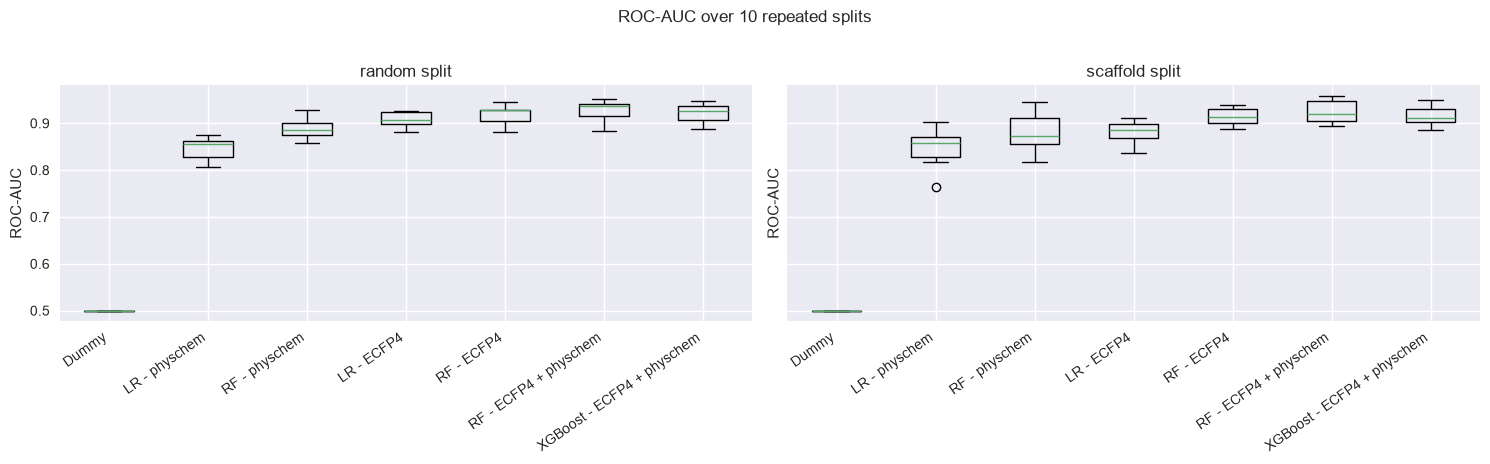

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, split_type in zip(axes, ["random", "scaffold"]):
    data = [results[(results["split"] == split_type) & (results["model"] == m)]["roc_auc"] for m in model_order]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(model_order) + 1))
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.set_title(f"{split_type} split")
    ax.set_ylabel("ROC-AUC")
plt.suptitle("ROC-AUC over 10 repeated splits", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_roc_auc_random_vs_scaffold.png", dpi=150, bbox_inches="tight")
plt.show()

### How optimistic is the random split?

Difference in mean ROC-AUC (random minus scaffold) per model, together with the nearest-neighbour similarity from
section 4.

split,random,scaffold,optimism (random - scaffold)
model,,,
Dummy,0.500,0.500,0.000
LR - physchem,0.847,0.849,-0.003
RF - physchem,0.889,0.882,0.008
LR - ECFP4,0.909,0.883,0.026
RF - ECFP4,0.919,0.915,0.004
RF - ECFP4 + physchem,0.928,0.924,0.003
XGBoost - ECFP4 + physchem,0.922,0.916,0.007


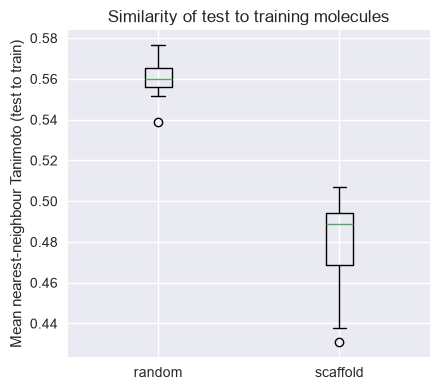

In [10]:
auc = results.pivot_table(index="model", columns="split", values="roc_auc", aggfunc="mean").loc[model_order]
auc["optimism (random - scaffold)"] = auc["random"] - auc["scaffold"]
auc.round(4).to_csv(RESULTS_DIR / "02_optimism.csv")
display(auc.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.boxplot([sim_df[sim_df["split"] == s]["mean_nn_similarity"] for s in ["random", "scaffold"]])
ax.set_xticks([1, 2])
ax.set_xticklabels(["random", "scaffold"])
ax.set_ylabel("Mean nearest-neighbour Tanimoto (test to train)")
ax.set_title("Similarity of test to training molecules")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_nn_similarity.png", dpi=150)
plt.show()

### Paired comparison under the scaffold split

All models see identical splits within a repeat, so differences can be paired. The table shows, for each model against
the physicochemical logistic regression, the mean difference in ROC-AUC, its standard deviation across repeats and the
share of repeats in which the model is better. With only 10 repeats this is a rough guide, not a significance test.

In [11]:
wide = (results[results["split"] == "scaffold"]
        .pivot(index="repeat", columns="model", values="roc_auc")[model_order])

reference = "LR - physchem"
rows = []
for m in model_order:
    if m in ("Dummy", reference):
        continue
    diff = wide[m] - wide[reference]
    rows.append({"model": m, "mean_diff": diff.mean(), "std_diff": diff.std(),
                 "share_better": (diff > 0).mean()})

paired = pd.DataFrame(rows).set_index("model")
paired.to_csv(RESULTS_DIR / "02_paired_vs_physchem_lr_scaffold.csv")
paired.round(3)

,mean_diff,std_diff,share_better
model,,,
RF - physchem,0.032,0.028,0.9
LR - ECFP4,0.033,0.028,0.9
RF - ECFP4,0.065,0.034,1.0
RF - ECFP4 + physchem,0.075,0.030,1.0
XGBoost - ECFP4 + physchem,0.066,0.036,1.0


**How to read this:** A model counts as clearly better only if the difference is positive in (almost) all repeats
and larger than its spread. Gains that are smaller than the repeat-to-repeat spread are not evidence of a better model.
A descriptor baseline that matches the fingerprint models is a legitimate result.

## Findings (fill in after running)

1. **Split optimism:** The random split overstates ROC-AUC only marginally (difference between -0.003 and +0.026
   per model, within the spread across repeats), although the mean nearest-neighbour similarity to the training set
   is clearly lower for scaffold test sets (0.479 vs 0.560). The randomised scaffold split used here is therefore
   mild and not comparable with deterministic scaffold-split benchmarks.
2. **Baseline strength:** Under the scaffold split, the random forest on ECFP4 and physicochemical descriptors
   (ROC-AUC 0.924) beats the descriptor logistic regression (0.849) by 0.075 in all 10 repeats. Against the
   descriptor random forest (0.882) the gain is 0.043.
3. **Best model:** The combined random forest has the highest mean ROC-AUC; XGBoost (untuned) is slightly lower
   (-0.009 in 9 of 10 repeats).
4. **Metrics:** PR-AUC is compressed by the 77 % positive rate. Balanced accuracy at a fixed threshold of 0.5
   ranks the models differently from ROC-AUC, so thresholds should be chosen inside the training data.

## Limitations

- Hyperparameters are fixed and untuned.
- The scaffold split depends on the random order of groups, so results are reported as spread over 10 repeats.
- Murcko scaffolds are a coarse similarity notion (very generic scaffolds such as plain benzene form one big group).
- Labels come from heterogeneous sources, and the label noise visible in the exact duplicates (20 conflicting rows) suggests
  an upper bound on achievable performance.
- The test sets contain about 390 molecules, so single-split metrics are noisy.

**Next:** `03_tuning_and_error_analysis.ipynb` – nested, scaffold-grouped tuning, a graph neural network as comparison and
an error analysis by scaffold family.